<a href="https://colab.research.google.com/github/amyxue-svg/MSSP6070/blob/main/Modules/Week13/Participation_Activity_Week13.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [32]:
import pandas as pd
import yfinance as yf
import datetime

In [33]:
startDate = datetime.datetime(2019, 1, 1)
endDate = datetime.datetime(2023, 12, 31)

In [34]:
Amazon = yf.Ticker("AMZN")
Apple = yf.Ticker("AAPL")
Meta = yf.Ticker("META")
Google = yf.Ticker("GOOGL")
Netflix = yf.Ticker("NFLX")

In [35]:
AMZN = pd.DataFrame(Amazon.history(start=startDate,end=endDate))
AMZN['Symbol']='AMZN'

AAPL = pd.DataFrame(Apple.history(start=startDate,end=endDate))
AAPL['Symbol']='AAPL'

META = pd.DataFrame(Meta.history(start=startDate,end=endDate))
META['Symbol']='META'

GOOGLE = pd.DataFrame(Google.history(start=startDate,end=endDate))
GOOGLE['Symbol']='GOOGL'

NETFLIX = pd.DataFrame(Netflix.history(start=startDate,end=endDate))
NETFLIX['Symbol']='NFLX'

In [36]:
stock_df = pd.DataFrame()

ticker_df = [AMZN, AAPL, META, GOOGLE, NETFLIX]

for ticker in ticker_df:
    stock_df = pd.concat(ticker_df)
stock_df

,Open,High,Low,Close,Volume,Dividends,Stock Splits,Symbol
Date,,,,,,,,
2019-01-02 00:00:00-05:00,73.260002,77.667999,73.046501,76.956497,159662000,0.0,0.0,AMZN
2019-01-03 00:00:00-05:00,76.000504,76.900002,74.855499,75.014000,139512000,0.0,0.0,AMZN
2019-01-04 00:00:00-05:00,76.500000,79.699997,75.915497,78.769501,183652000,0.0,0.0,AMZN
2019-01-07 00:00:00-05:00,80.115501,81.727997,79.459503,81.475502,159864000,0.0,0.0,AMZN
2019-01-08 00:00:00-05:00,83.234497,83.830498,80.830498,82.829002,177628000,0.0,0.0,AMZN
...,...,...,...,...,...,...,...,...
2023-12-22 00:00:00-05:00,49.400002,49.602001,48.544998,48.675999,27027000,0.0,0.0,NFLX
2023-12-26 00:00:00-05:00,48.938999,49.147999,48.638000,49.118999,20345000,0.0,0.0,NFLX
2023-12-27 00:00:00-05:00,49.124001,49.402000,48.924999,49.179001,25613000,0.0,0.0,NFLX


In [37]:
financial_metrics = [
    'quickRatio', 'currentRatio', 'totalRevenue', 'debtToEquity',
    'revenuePerShare', 'returnOnAssets', 'returnOnEquity', 'grossProfits'
]

tickers = ["AMZN", "AAPL", "META", "GOOGL", "NFLX"]

financial_data = {}

for ticker_symbol in tickers:
    stock_ticker = yf.Ticker(ticker_symbol)
    info = stock_ticker.info

    metrics_for_ticker = {metric: info.get(metric) for metric in financial_metrics}
    financial_data[ticker_symbol] = metrics_for_ticker
financial_df = pd.DataFrame(financial_data).T
financial_df.index.name = 'Ticker'

print("Financial Metrics for Each Stock:")
print(financial_df)

Financial Metrics for Each Stock:
        quickRatio  currentRatio  totalRevenue  debtToEquity  revenuePerShare  \
Ticker                                                                          
AMZN         0.793         0.989  7.974550e+11        49.681           74.147   
AAPL         0.827         1.023  4.788340e+11        84.286           32.658   
META         1.669         1.903  2.416050e+11        42.161           95.186   
GOOGL        2.512         2.786  4.710980e+11        22.187           38.789   
NFLX         0.836         1.075  4.973463e+10        59.857           11.860   

        returnOnAssets  returnOnEquity  grossProfits  
Ticker                                                
AMZN           0.06618         0.27416  4.096820e+11  
AAPL           0.25868         1.42257  2.336020e+11  
META           0.14577         0.32264  1.957820e+11  
GOOGL          0.12743         0.44286  2.866980e+11  
NFLX           0.17124         0.53463  2.520779e+10  


In [38]:
import matplotlib.pyplot as plt
import seaborn as sns

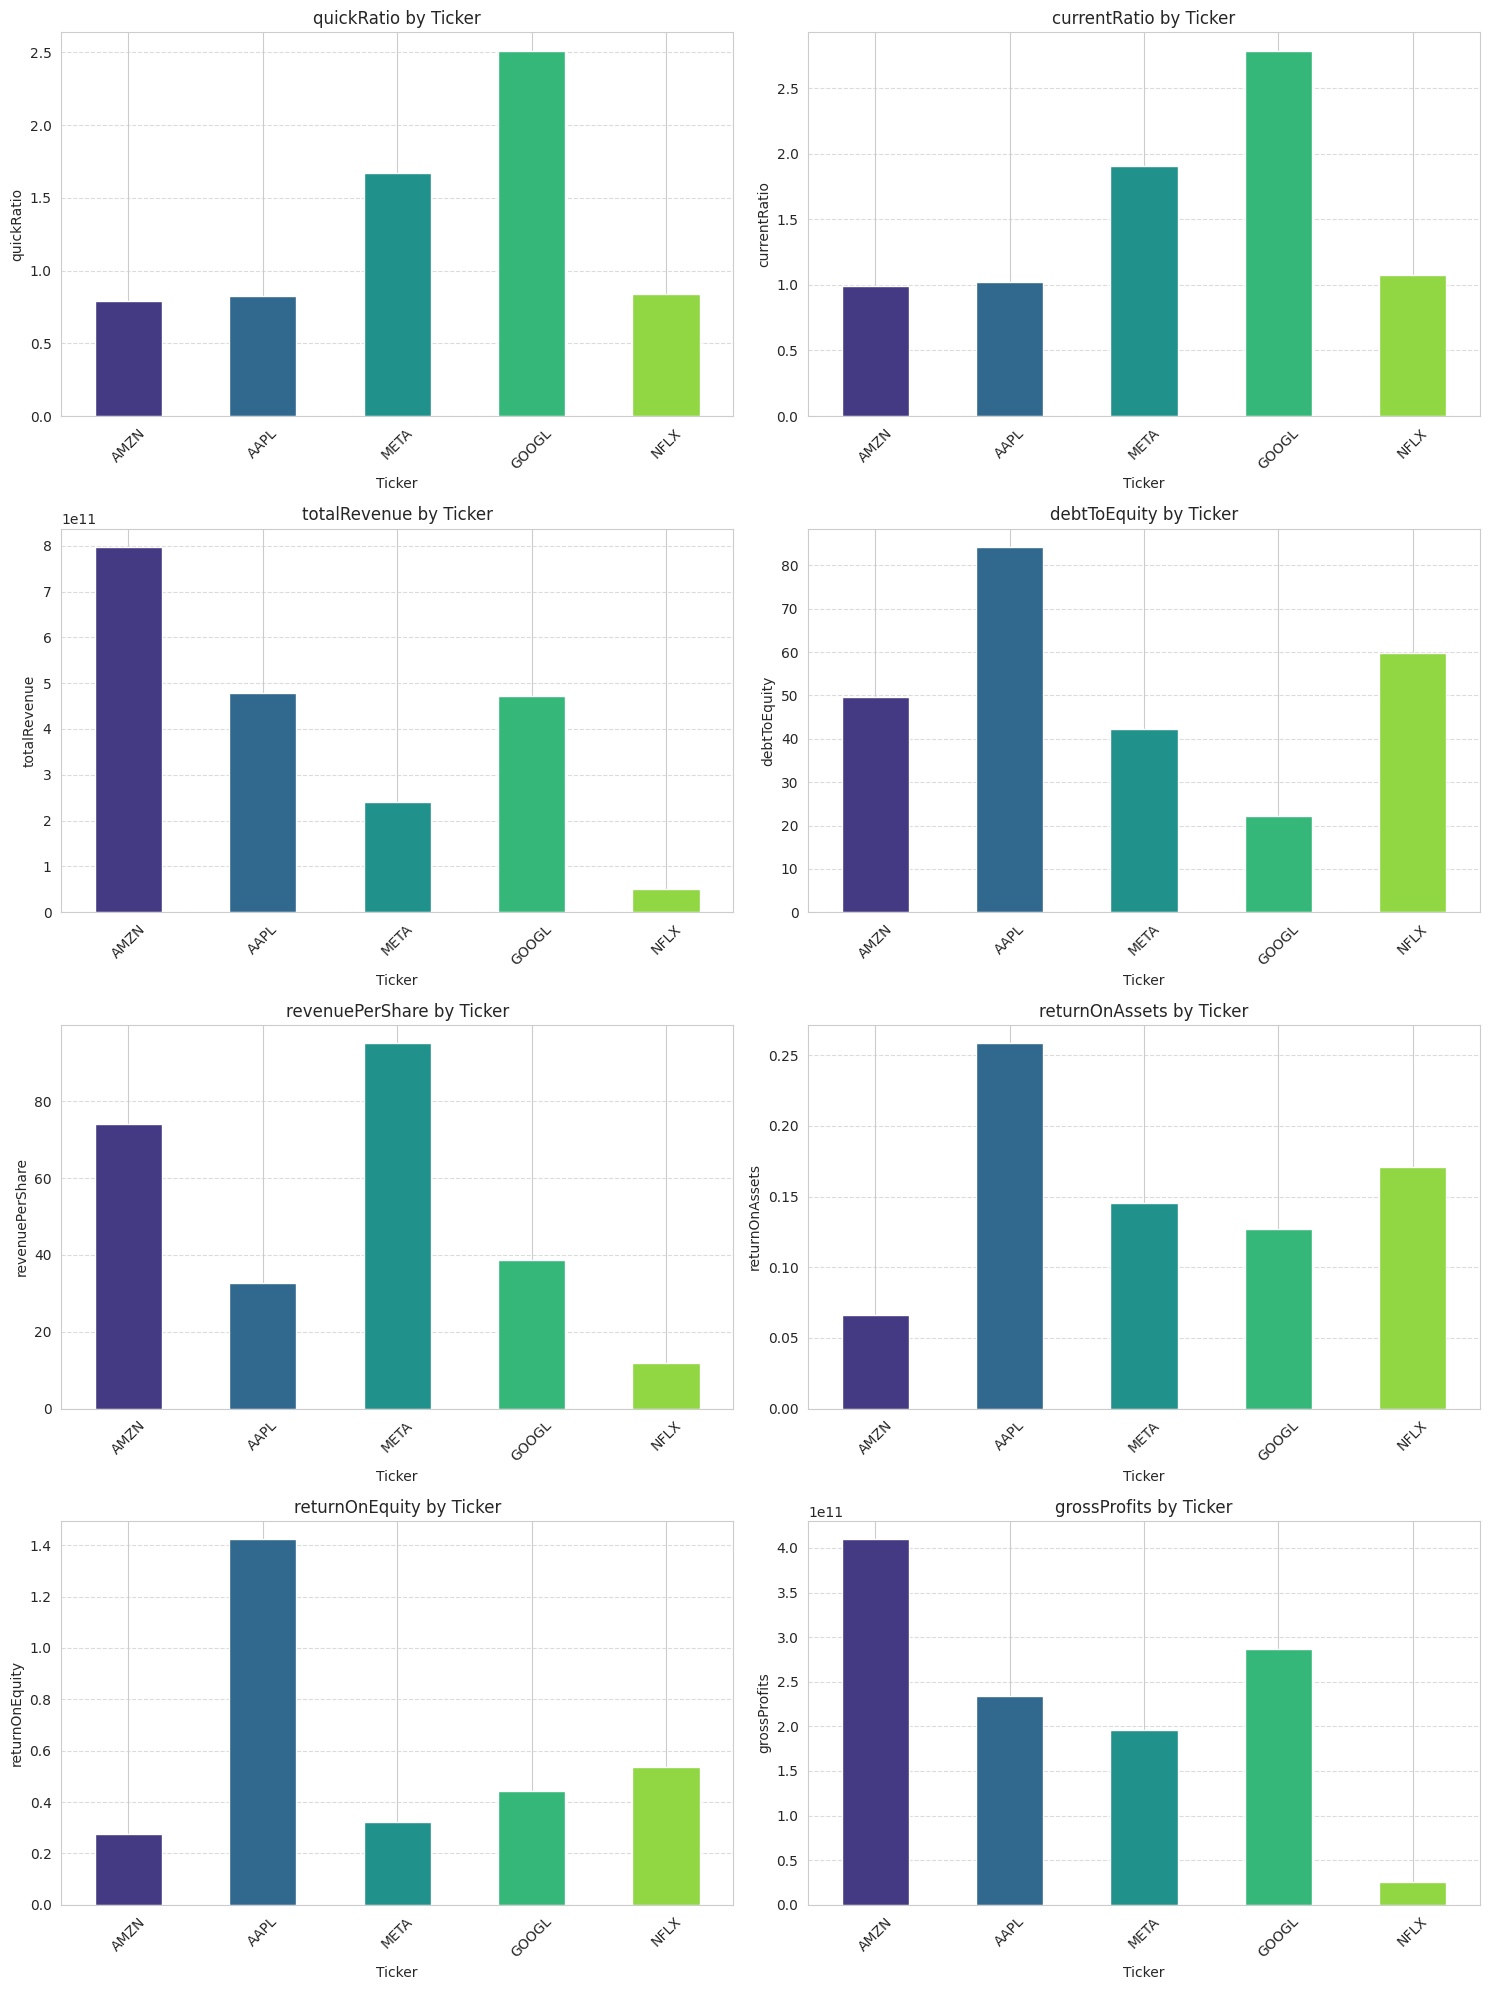

In [39]:
sns.set_style("whitegrid")

num_metrics = len(financial_metrics)
num_cols = 2
num_rows = (num_metrics + num_cols - 1) // num_cols

fig, axes = plt.subplots(num_rows, num_cols, figsize=(15, 5 * num_rows))
axes = axes.flatten()

for i, metric in enumerate(financial_metrics):
    ax = axes[i]
    financial_df[metric].plot(kind='bar', ax=ax, color=sns.color_palette("viridis", len(financial_df)))
    ax.set_title(f'{metric} by Ticker')
    ax.set_ylabel(metric)
    ax.tick_params(axis='x', rotation=45)
    ax.grid(axis='y', linestyle='--', alpha=0.7)

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

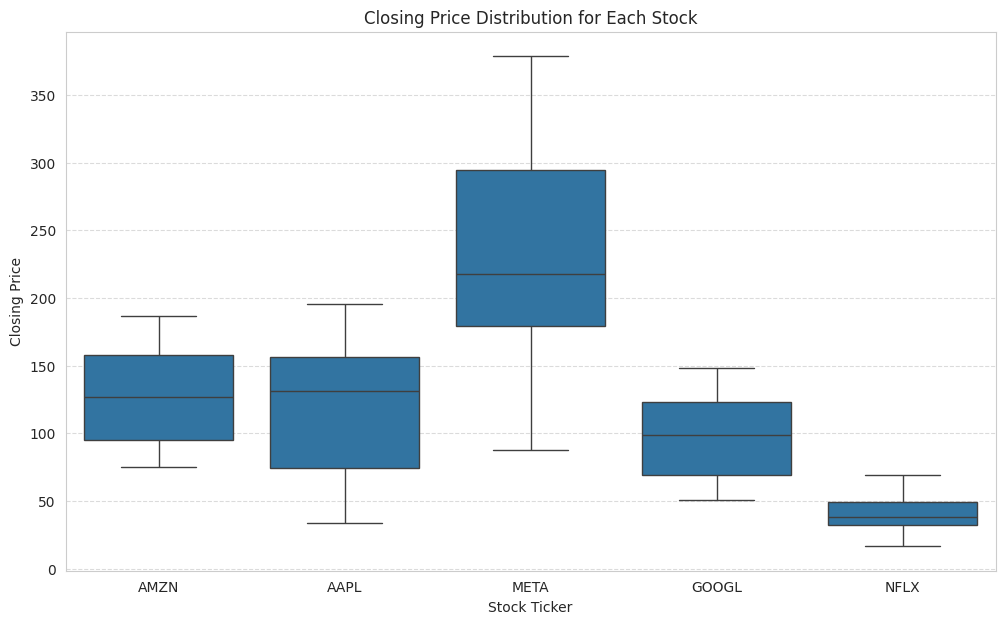

In [40]:
if not isinstance(stock_df.index, pd.DatetimeIndex):
    stock_df.index = pd.to_datetime(stock_df.index)

plt.figure(figsize=(12, 7))
sns.boxplot(x='Symbol', y='Close', data=stock_df)
plt.title('Closing Price Distribution for Each Stock')
plt.xlabel('Stock Ticker')
plt.ylabel('Closing Price')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

<Axes: xlabel='Symbol', ylabel='Close'>

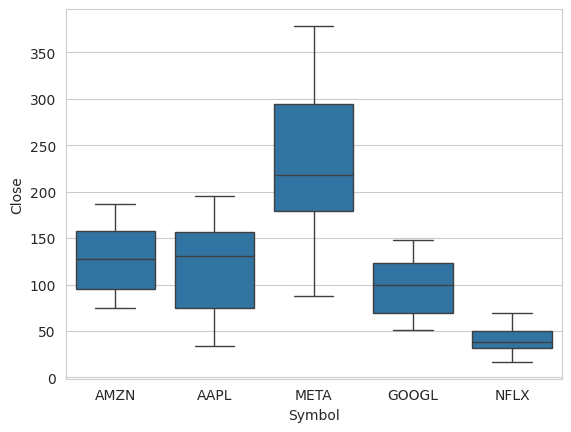

In [41]:
sns.boxplot(x='Symbol', y='Close', data=stock_df)

In [42]:
stock_df = stock_df.reset_index()

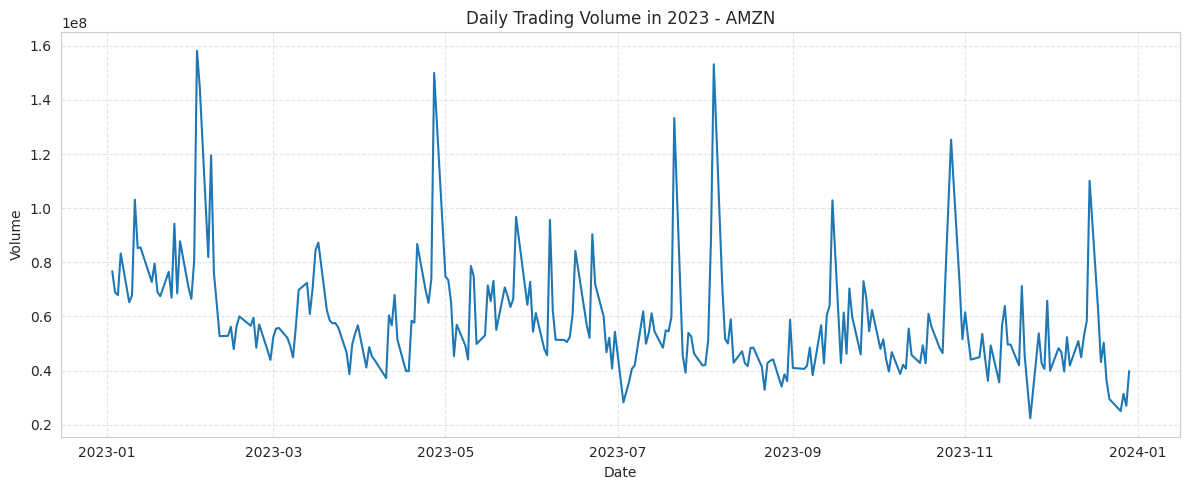

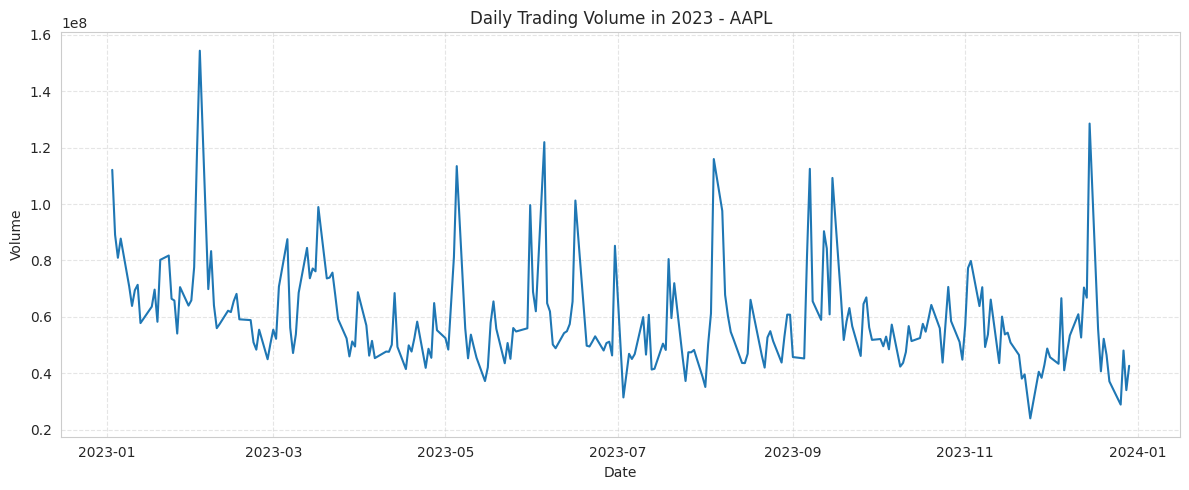

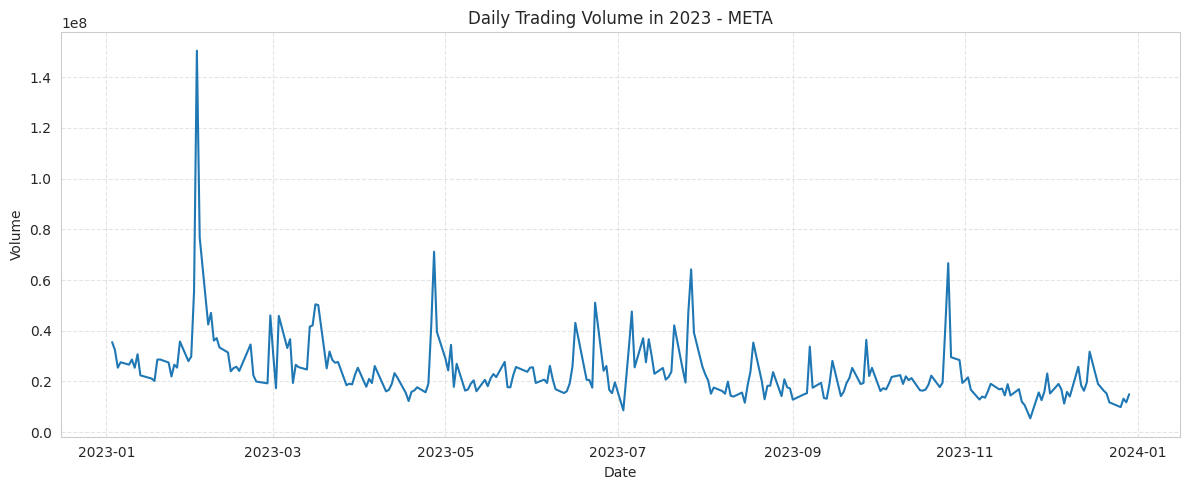

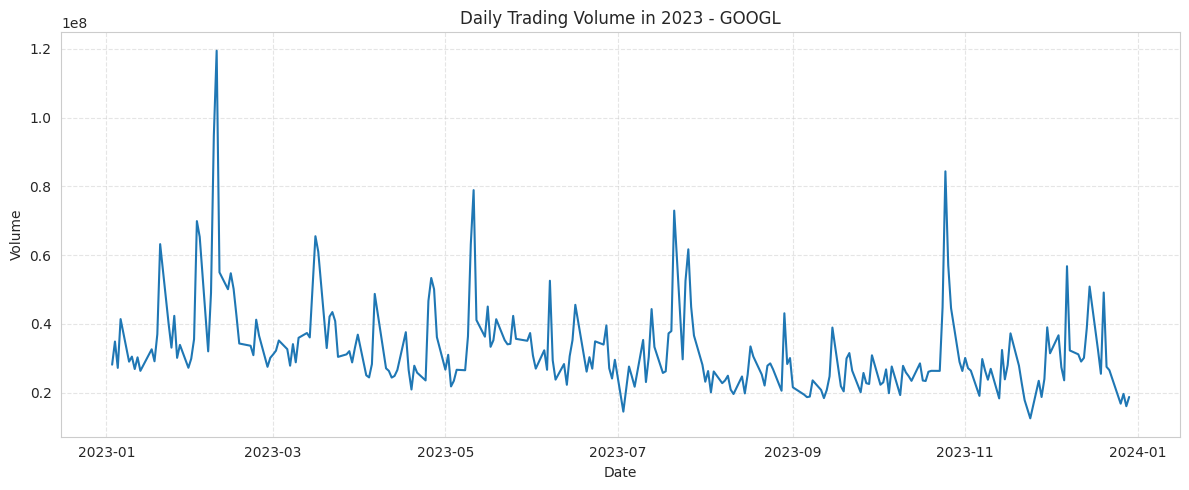

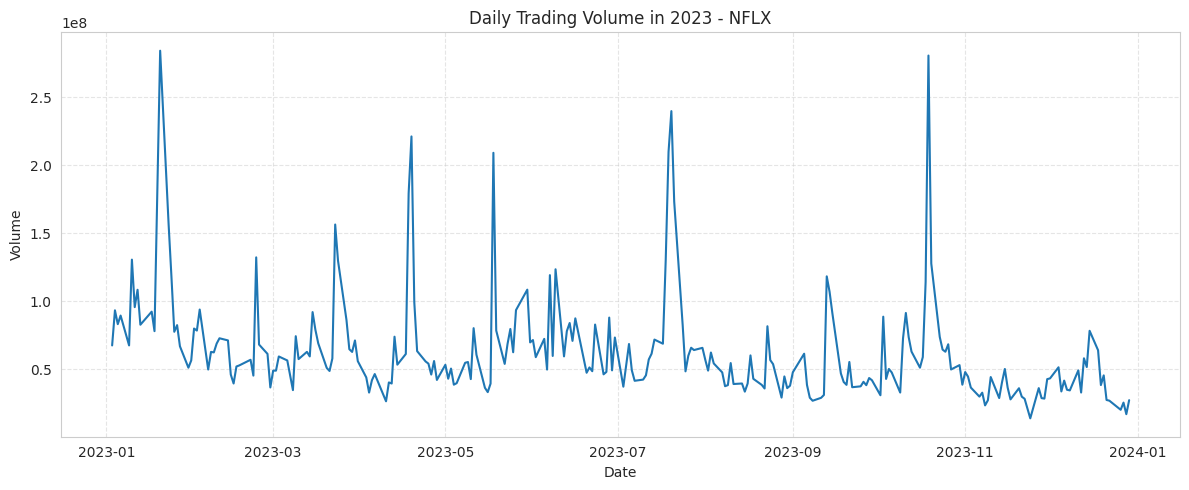

In [43]:
stock_df['Date'] = pd.to_datetime(stock_df['Date'])

stock_df_2023 = stock_df[stock_df['Date'].dt.year == 2023]

tickers = stock_df_2023['Symbol'].unique()

for ticker in tickers:
    df_t = stock_df_2023[stock_df_2023['Symbol'] == ticker].sort_values(by='Date')

    plt.figure(figsize=(12, 5))
    plt.plot(df_t['Date'], df_t['Volume'], linewidth=1.5)

    plt.title(f"Daily Trading Volume in 2023 - {ticker}")
    plt.xlabel("Date")
    plt.ylabel("Volume")
    plt.grid(True, linestyle='--', alpha=0.5)

    plt.tight_layout()
    plt.show()

In [44]:
from google.colab import files
files.download('StockData.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>